# OVM Assignment 1



### 1
Plot daily close prices


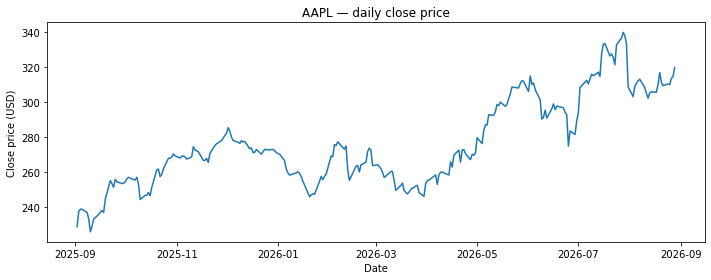

In [6]:
import matplotlib.pyplot as plt
import yfinance as yf

# Download daily prices (end date is exclusive, so we use 1 Sep 2026)
close = yf.Ticker("AAPL").history(start="2025-09-01", end="2026-08-31")["Close"]

plt.figure(figsize=(10, 4))
plt.plot(close)
plt.title("AAPL — daily close price")
plt.xlabel("Date")
plt.ylabel("Close price (USD)")
plt.tight_layout()
plt.show()


Compute the daily return and daily logarithmic return and create plots to illustrate the patterns of both returns.


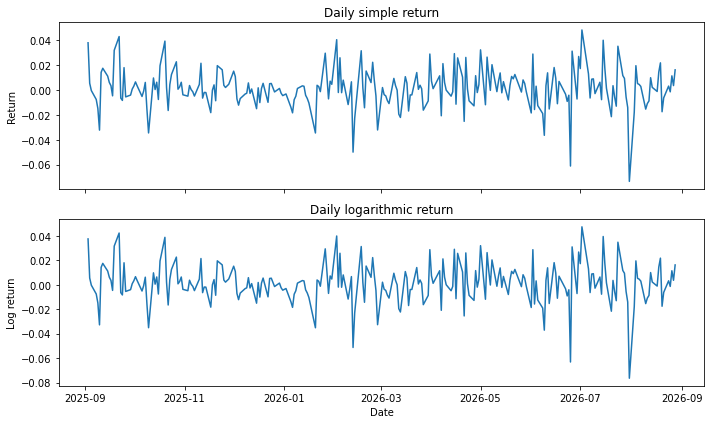

In [8]:
import numpy as np

# Simple daily return: (P_t - P_{t-1}) / P_{t-1}
daily_return = (close-close.shift(1))/close.shift(1)

# Log daily return: ln(P_t / P_{t-1})
log_return = np.log(close/close.shift(1))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(daily_return)
axes[0].set_title("Daily simple return")
axes[0].set_ylabel("Return")

axes[1].plot(log_return)
axes[1].set_title("Daily logarithmic return")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log return")

plt.tight_layout()
plt.show()


Explain under what circumstances these two types of returns can be considered approxi-
mately identical.

When change in price has a mean approaching 0 and a low variance, the two returns can pe considered approximately identical in accordance with the fact that the logarithm function is used to reduce the variance.

### b)
Plot the histogram of daily logarithmic returns, compute the sample mean ˆμ and variance
ˆσ2, and produce the quantile-quantile plot, i.e., daily logarithmic returns vs. normal
distribution N(ˆμ, ˆσ2).

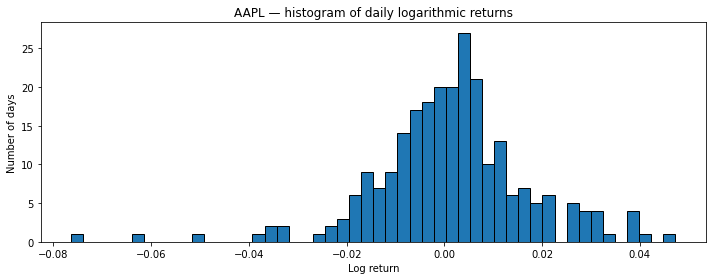

Sample mean: 0.0013422051860065257
Sample variance: 0.00025250212767940626


In [9]:
log_returns_clean=log_return.dropna()
plt.figure(figsize=(10, 4))
plt.hist(log_returns_clean, bins=50, edgecolor="black")
plt.title("AAPL — histogram of daily logarithmic returns")
plt.xlabel("Log return")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()


mean_lr=log_returns_clean.mean()
var_lr=log_returns_clean.var()
sd_lr=np.sqrt(var_lr)

print("Sample mean:", mean_lr)
print("Sample variance:", var_lr)



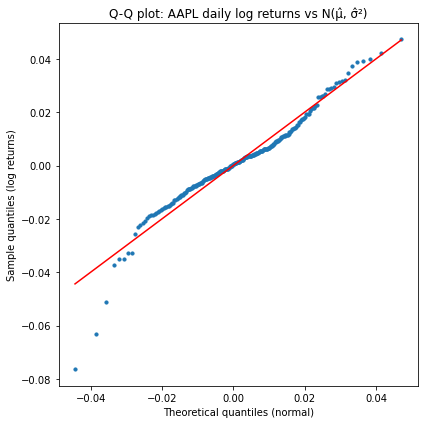

In [10]:
from scipy.stats import norm

sample_q=np.sort(log_returns_clean)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_lr,scale=sd_lr)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

Repeat the above process for the weekly close prices (4 years - 2022,2023,2024,2025), and
compare the Q Q plot patterns of weekly and daily returns.

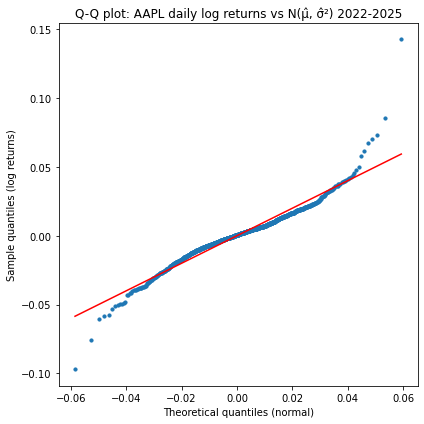

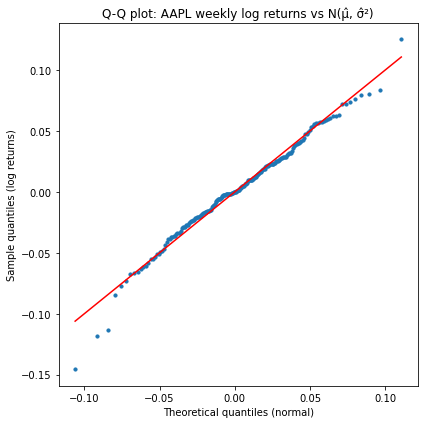

In [11]:
close_day = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31")["Close"]
close_week = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31", interval="1wk")["Close"]

day_log_returns=np.log(close_day/close_day.shift(1))
day_log_returns=day_log_returns.dropna()
mean_d=day_log_returns.mean()
var_d=day_log_returns.var()
sd_d=np.sqrt(var_d)


week_log_returns=np.log(close_week/close_week.shift(1))
week_log_returns=week_log_returns.dropna()
mean_w=week_log_returns.mean()
var_w=week_log_returns.var()
sd_w=np.sqrt(var_w)

sample_q=np.sort(day_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_d,scale=sd_d)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²) 2022-2025")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()


sample_q=np.sort(week_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_w,scale=sd_w)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL weekly log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()



### 2
Monte Carlo
Compute the expected value of 1/
√
U for U ∼ U(0, 1) using Monte Carlo method.

E[1/sqrt(U)]=1/E[U]=1/(1/2)=2

In [13]:
rng=np.random.default_rng(seed=41)

n=1000

U=rng.uniform(0,1,n)
y=1/np.sqrt(U)

estimate=y.mean()
print("Monte Carlo estimate:", estimate)
print("Absolute error:", abs(estimate - 2))


Monte Carlo estimate: 2.010818219349918
Absolute error: 0.01081821934991778


Study the speed of convergence of MC method and whether the errors are asymptotically normal. Discuss your results.

To support your discussion produce figures with estimates and confidence intervals of these estimates for different number of samples $10^2, 10^3, 10^4, 10^5$. To test normality of errors show figures of the histogram together with the normal density with estimated parameters as well as Q-Q plot.

N=   100: estimate=1.9186, 95% CI=[1.5504, 2.2868]
N=  1000: estimate=1.9650, 95% CI=[1.7618, 2.1682]
N= 10000: estimate=2.0087, 95% CI=[1.9547, 2.0628]
N=100000: estimate=2.0364, 95% CI=[1.9363, 2.1366]


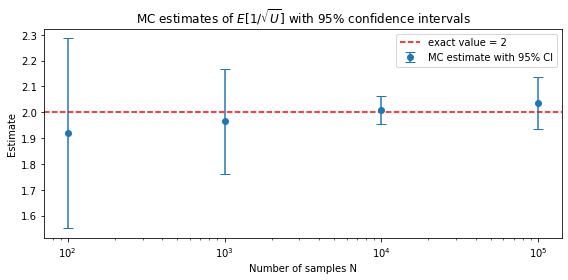

In [ ]:
# One MC estimate and its 95% confidence interval for each sample size
Ns=[10**2,10**3,10**4,10**5,10**6,10**7]
estimates=[]
half_widths=[]

for n in Ns:
    y=1/np.sqrt(rng.uniform(0,1,n))
    est=y.mean()
    se=y.std(ddof=1)/np.sqrt(n)
    estimates.append(est)
    half_widths.append(1.96*se)
    print(f"N={n:>6}: estimate={est:.4f}, 95% CI=[{est-1.96*se:.4f}, {est+1.96*se:.4f}]")

plt.figure(figsize=(8, 4))
plt.errorbar(Ns,estimates,yerr=half_widths,fmt="o",capsize=5,label="MC estimate with 95% CI")
plt.axhline(2,color="red",linestyle="--",label="exact value = 2")
plt.xscale("log")
plt.title("MC estimates of $E[1/\sqrt{U}]$ with 95% confidence intervals")
plt.xlabel("Number of samples N")
plt.ylabel("Estimate")
plt.legend()
plt.tight_layout()
plt.show()

N=   100: mean |error|=0.18997, CI coverage=0.861
N=  1000: mean |error|=0.07448, CI coverage=0.894
N= 10000: mean |error|=0.02601, CI coverage=0.913
N=100000: mean |error|=0.00871, CI coverage=0.942


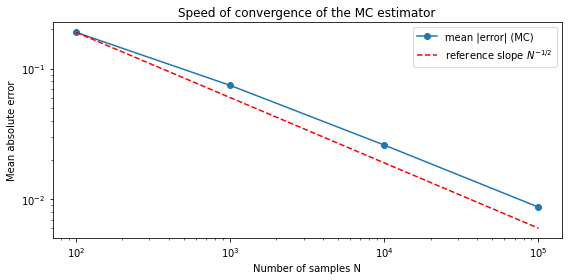

In [15]:
# Repeat the MC experiment M times for each N to study the distribution of the error
M=1000
errors={}
coverage={}

for n in Ns:
    err=np.empty(M)
    inside=0
    for m in range(M):
        y=1/np.sqrt(rng.uniform(0,1,n))
        est=y.mean()
        se=y.std(ddof=1)/np.sqrt(n)
        err[m]=est-2
        inside+=abs(est-2)<=1.96*se
    errors[n]=err
    coverage[n]=inside/M
    print(f"N={n:>6}: mean |error|={np.abs(err).mean():.5f}, CI coverage={coverage[n]:.3f}")

mean_abs_err=[np.abs(errors[n]).mean() for n in Ns]

plt.figure(figsize=(8, 4))
plt.loglog(Ns,mean_abs_err,"o-",label="mean |error| (MC)")
plt.loglog(Ns,mean_abs_err[0]*np.sqrt(Ns[0])/np.sqrt(Ns),"--",color="red",label="reference slope $N^{-1/2}$")
plt.title("Speed of convergence of the MC estimator")
plt.xlabel("Number of samples N")
plt.ylabel("Mean absolute error")
plt.legend()
plt.tight_layout()
plt.show()

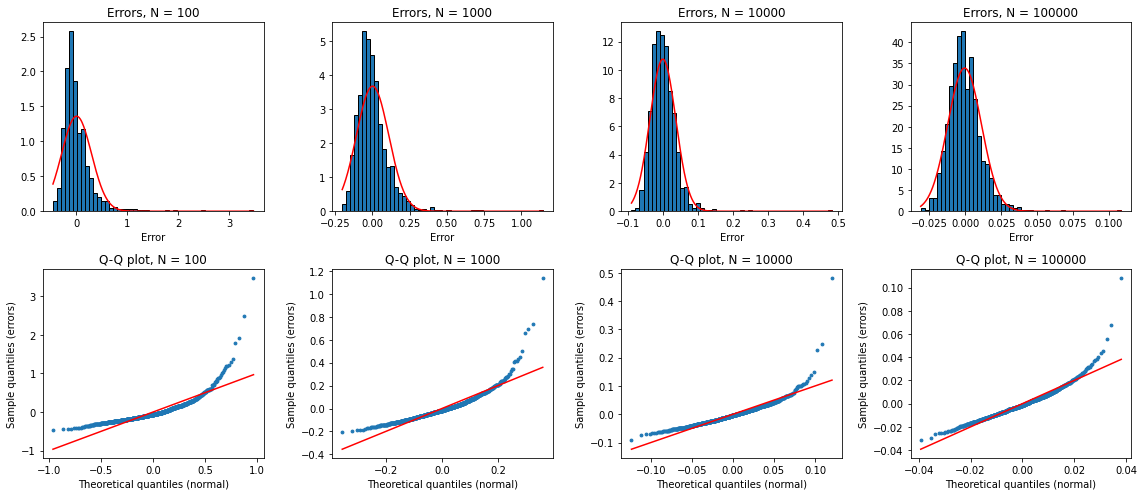

In [17]:
# Histogram of errors with fitted normal density (top) and Q-Q plot vs fitted normal (bottom)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for j, n in enumerate(Ns):
    err=errors[n]
    mu=err.mean()
    sd=err.std(ddof=1)

    x=np.linspace(err.min(),err.max(),400)
    axes[0, j].hist(err,bins=50,density=True,edgecolor="black")
    axes[0, j].plot(x,norm.pdf(x,loc=mu,scale=sd),color="red")
    axes[0, j].set_title(f"Errors, N = {n}")
    axes[0, j].set_xlabel("Error")

    sample_q=np.sort(err)
    probabilities=(np.arange(1,M+1)-0.5)/M
    theory_q=norm.ppf(probabilities,loc=mu,scale=sd)
    axes[1, j].scatter(theory_q,sample_q,s=8)
    axes[1, j].plot(theory_q,theory_q,color="red")
    axes[1, j].set_title(f"Q-Q plot, N = {n}")
    axes[1, j].set_xlabel("Theoretical quantiles (normal)")
    axes[1, j].set_ylabel("Sample quantiles (errors)")

plt.tight_layout()
plt.show()

Speed of convergence:  The estimates get closer to the exact value 2 as N grows and the confidence intervals get narrower. On the log-log plot the mean absolute error falls by a factor of roughly 3 for every tenfold increase in N, so it follows the reference slope $N^{-1/2}$ closely. The decrease is slightly slower than $\sqrt{10}\approx 3.16$ because the variance is infinite.

Normality of the errors. The classical CLT needs a finite variance, so it does not apply directly. The histograms are clearly right-skewed, with a long right tail. Rare samples with very small $U$ produce huge values of $1/\sqrt{U}$ and pull the estimate up. The fitted normal density does not match the histogram shape. In the Q-Q plots the points bend away from the red line in the right tail. This departure is strongest for $N=10^2$ and becomes milder as N grows.

Confidence intervals. Because the errors are not normal and the sample standard deviation underestimates the true spread, the usual 95% intervals $\hat\mu \pm 1.96\, s/\sqrt{N}$ cover the true value less often than 95% of the time. This is worst for small N. Coverage improves towards 95% as N grows, but slowly, so these intervals should be read with caution for this integrand. The infinite variance also makes the sample standard deviation unstable: one very small $U$ can inflate it, so a larger N does not always give a narrower interval in a single run.